# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

In [1]:
import time
import timeit
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')


raw = pd.read_csv('data/Orange_Telecom_Churn_Data.csv')
print(raw.shape)
raw.head(3).T

(5000, 21)


,0,1,2
state,KS,OH,NJ
account_length,128,107,137
area_code,415,415,415
phone_number,382-4657,371-7191,358-1921
intl_plan,no,no,no
voice_mail_plan,yes,yes,no
number_vmail_messages,25,26,0
total_day_minutes,265.1,161.6,243.4
total_day_calls,110,123,114
total_day_charge,45.07,27.47,41.38


### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [4]:
import pandas as pd

# категориальные колонки: удалённые в ноутбуке (state, area_code, phone_number)
# и оставшиеся (intl_plan, voice_mail_plan)
cat_cols = ['state', 'area_code', 'phone_number', 'intl_plan', 'voice_mail_plan']

cardinality = raw[cat_cols].nunique().sort_values(ascending=False)
print(cardinality)

# сколько столбцов получилось бы при one-hot (n-1 на колонку) и какой объём памяти нужен
n_rows = len(raw)
for col in cat_cols:
    n_cols = raw[col].nunique() - 1
    mb = n_rows * n_cols * 8 / 1024 ** 2   # плотная матрица float64
    print(f'{col:16s} -> {n_cols:5d} столбцов, плотная матрица ~ {mb:8.1f} МБ')

phone_number       5000
state                51
area_code             3
intl_plan             2
voice_mail_plan       2
dtype: int64
state            ->    50 столбцов, плотная матрица ~      1.9 МБ
area_code        ->     2 столбцов, плотная матрица ~      0.1 МБ
phone_number     ->  4999 столбцов, плотная матрица ~    190.7 МБ
intl_plan        ->     1 столбцов, плотная матрица ~      0.0 МБ
voice_mail_plan  ->     1 столбцов, плотная матрица ~      0.0 МБ


In [5]:
from sklearn.preprocessing import OneHotEncoder

# one-hot по phone_number: каждая строка получает единицу в "своём" столбце
ohe_phone = OneHotEncoder(handle_unknown='ignore')
phone_ohe = ohe_phone.fit_transform(raw[['phone_number']])
print('Размер матрицы:', phone_ohe.shape)
print('Ненулевых элементов:', phone_ohe.nnz, 'из', phone_ohe.shape[0] * phone_ohe.shape[1])

# евклидово расстояние между двумя РАЗНЫМИ клиентами только по этому блоку
a = phone_ohe[0].toarray().ravel()
b = phone_ohe[1].toarray().ravel()
print('Расстояние между клиентами 0 и 1:', np.sqrt(((a - b) ** 2).sum()))

Размер матрицы: (5000, 5000)
Ненулевых элементов: 5000 из 25000000
Расстояние между клиентами 0 и 1: 1.4142135623730951


**Что мы сделали:** посчитали число уникальных значений в каждой категориальной колонке. `state` - 51 значение, `area_code` - 3, `intl_plan` и `voice_mail_plan` - по 2, а `phone_number` - **5000 значений на 5000 строк**, то есть уникален для каждого клиента. Затем проверили, что получится при one-hot кодировании `phone_number`.

**Почему это плохо для KNN (математически):**

1. *Пространство.* One-hot колонки с $n$ категориями даёт $n-1$ (или $n$) новых признаков. Для `phone_number` это матрица $5000 \times 5000$ (25 млн элементов, в плотном виде около 190 МБ), причём в каждой строке ровно одна единица. Размерность пространства вырастает с 17 до примерно 5000, а объектов по-прежнему 5000. При $d \gg N$ данные в пространстве очень разрежены.
2. *Расстояния ничего не говорят о сходстве.* У двух разных клиентов единицы стоят в разных столбцах, поэтому для любой пары $x_i \ne x_j$ получаем $\|x_i - x_j\|_2 = \sqrt{1^2 + 1^2} = \sqrt{2}$, одинаково для всех пар. Номер телефона - это просто идентификатор, он не связан с оттоком, и этот блок признаков не несёт полезной информации, но добавляет в расстояние постоянное слагаемое и «разбавляет» 17 настоящих признаков.
3. *Переобучение.* В обучающей выборке расстояние от точки до самой себя по этому блоку равно 0, а до любой другой - $\sqrt{2}$. Поэтому при $K=1$ (или при `weights='distance'`) ближайшим соседом всегда оказывается сама точка, и модель просто запоминает обучающую выборку (точность на train 100%). На новых данных номер телефона не совпадает ни с одним из обученных, и этот признак ничего не даёт.
4. Для `LabelBinarizer` те же рассуждения. А если закодировать номер просто числами (`LabelEncoder`), то появится ложный порядок: клиент №100 «ближе» к №101, чем к №4000, хотя это бессмысленно.

Поэтому `phone_number` удаляют. `state` (51 значение) тоже сомнительный признак: он добавляет 50 столбцов, которые могут перевесить числовые признаки в расстоянии, а `area_code` содержит всего 3 значения и, как правило, мало информативен.

### Подготовка данных (общая для упражнений 2-12)
Удаляем `state`, `area_code`, `phone_number` (см. упражнение 1), бинарные колонки `intl_plan`, `voice_mail_plan`, `churned` переводим в 0/1. Для честной оценки разбиваем данные на обучающую и тестовую части (70/30, с сохранением доли классов), а масштабирование везде подгоняем только на обучающей части.

In [6]:
data = raw.drop(columns=['state', 'area_code', 'phone_number']).copy()

# yes/no -> 1/0, churned True/False -> 1/0
for col in ['intl_plan', 'voice_mail_plan']:
    data[col] = (data[col] == 'yes').astype(int)
data['churned'] = data['churned'].astype(int)

X = data.drop(columns='churned')
y = data['churned']

print('Признаков:', X.shape[1])
print('Доля ушедших клиентов: %.3f' % y.mean())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape)

Признаков: 17
Доля ушедших клиентов: 0.141
(3500, 17) (1500, 17)


In [7]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# масштабируем: fit только на train
scaler = MinMaxScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# вся выборка целиком (нужна только для упражнения 5, где разбиения нет)
X_all_s = MinMaxScaler().fit_transform(X)

### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [8]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

two = raw[['account_length', 'total_day_charge']]
print(two.describe().loc[['min', 'max', 'std']])

# два клиента: почти одинаковый account_length, но сильно разный total_day_charge
c1 = np.array([100.0, 10.0])
c2 = np.array([110.0, 50.0])
c3 = np.array([200.0, 12.0])   # давно клиент, а дневной счёт близок к c1

def dist(a, b):
    return np.sqrt(((a - b) ** 2).sum())

print('\nБез масштабирования:')
print('d(c1, c2) =', round(dist(c1, c2), 2), ' (account_length: 10, charge: 40)')
print('d(c1, c3) =', round(dist(c1, c3), 2), ' (account_length: 100, charge: 2)')

# то же после MinMaxScaler (подгоняем на всех данных двух признаков)
mm = MinMaxScaler().fit(two)
s1, s2, s3 = mm.transform(pd.DataFrame([c1, c2, c3], columns=two.columns))
print('\nПосле MinMaxScaler:')
print('d(c1, c2) =', round(dist(s1, s2), 3))
print('d(c1, c3) =', round(dist(s1, s3), 3))

     account_length  total_day_charge
min         1.00000          0.000000
max       243.00000         59.760000
std        39.69456          9.162069

Без масштабирования:
d(c1, c2) = 41.23  (account_length: 10, charge: 40)
d(c1, c3) = 100.02  (account_length: 100, charge: 2)

После MinMaxScaler:
d(c1, c2) = 0.671
d(c1, c3) = 0.415


In [9]:
# Что будет при выбросах: добавим к total_day_charge один сильный выброс
col = raw['total_day_charge'].copy()
col_out = pd.concat([col, pd.Series([1000.0])], ignore_index=True)   # выброс = 1000

def bulk_spread(values, scaler):
    scaled = scaler.fit_transform(values.to_frame()).ravel()[:-1]    # без выброса
    return scaled.std(), scaled.min(), scaled.max()

# без выброса
for name, sc in [('MinMax', MinMaxScaler()), ('Standard', StandardScaler())]:
    s = sc.fit_transform(col.to_frame()).ravel()
    print(f'Без выброса, {name:8s}: std={s.std():.3f}, min={s.min():.2f}, max={s.max():.2f}')

print()
for name, sc in [('MinMax', MinMaxScaler()), ('Standard', StandardScaler())]:
    std, mn, mx = bulk_spread(col_out, sc)
    print(f'С выбросом,  {name:8s}: разброс обычных клиентов std={std:.3f}, диапазон [{mn:.3f}; {mx:.3f}]')

Без выброса, MinMax  : std=0.153, min=0.00, max=1.00
Без выброса, Standard: std=1.000, min=-3.35, max=3.18

С выбросом,  MinMax  : разброс обычных клиентов std=0.009, диапазон [0.000; 0.060]
С выбросом,  Standard: разброс обычных клиентов std=0.556, диапазон [-1.871; 1.754]


**Что мы сделали:** взяли двух клиентов и сравнили расстояния до и после масштабирования, а затем добавили в `total_day_charge` искусственный выброс и посмотрели, как на него реагируют `MinMaxScaler` и `StandardScaler`.

**Без масштабирования** расстояние определяется признаком с большим разбросом значений: $d(c_1, c_3) = \sqrt{100^2 + 2^2} \approx 100$ получается намного больше, чем $d(c_1, c_2) = \sqrt{10^2 + 40^2} \approx 41$, хотя по дневному счёту $c_3$ почти не отличается от $c_1$. После `MinMaxScaler` оба признака вносят сопоставимый вклад, и порядок «ближе - дальше» меняется. Таким образом, без масштабирования KNN фактически смотрит только на признаки с большими числами.

**Выбросы.** `MinMaxScaler` использует минимум и максимум: $x' = (x - x_{min})/(x_{max} - x_{min})$. Один выброс растягивает диапазон, и все обычные клиенты «сжимаются» в узкий интервал около 0 (в нашем примере разброс обычных значений упал примерно в 17 раз: стандартное отклонение с 0,153 до 0,009). Различия между ними почти исчезают, и признак перестаёт влиять на расстояние. `StandardScaler` вычитает среднее и делит на стандартное отклонение, диапазона у него нет. Выброс тоже увеличивает $\sigma$ и сдвигает среднее, поэтому обычные значения тоже сжимаются, но слабее, чем у MinMax (в нашем примере std обычных значений 0,56 вместо 0,009), а сам выброс остаётся далеко (в единицах $\sigma$). Тем не менее ни один из них не устойчив к выбросам. Для данных с выбросами лучше `RobustScaler` (медиана и межквартильный размах) или предварительная обрезка/логарифм.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [10]:
import time
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Создание синтетических данных
np.random.seed(RANDOM_STATE)
X_syn = np.random.rand(100000, 10)
y_syn = np.random.randint(0, 2, 100000)
X_query = np.random.rand(2000, 10)     # объекты, для которых ищем соседей

def run_benchmark(label):
    # обучение (построение индекса) и предсказание измеряем отдельно через timeit
    fit_time = timeit.timeit(
        lambda: KNeighborsClassifier(n_neighbors=5).fit(X_syn, y_syn), number=3) / 3
    model = KNeighborsClassifier(n_neighbors=5).fit(X_syn, y_syn)
    pred_time = timeit.timeit(lambda: model.predict(X_query), number=1)
    print(f'{label:22s} fit: {fit_time:7.3f} c   predict (2000 запросов): {pred_time:7.3f} c')
    return fit_time, pred_time

# Измерение времени обучения без патча и с патчем
t_plain = run_benchmark('обычный scikit-learn')

try:
    from sklearnex import patch_sklearn, unpatch_sklearn
    patch_sklearn()
    # после патча нужно заново импортировать класс
    from sklearn.neighbors import KNeighborsClassifier
    t_intel = run_benchmark('с патчем Intel')
    print('Ускорение fit: x%.1f, predict: x%.1f' % (t_plain[0] / t_intel[0], t_plain[1] / t_intel[1]))
    unpatch_sklearn()
    from sklearn.neighbors import KNeighborsClassifier
except ImportError:
    print('Библиотека sklearnex не установлена (pip install scikit-learn-intelex), патч не измерялся')

обычный scikit-learn   fit:   0.148 c   predict (2000 запросов):   0.384 c
с патчем Intel         fit:   0.026 c   predict (2000 запросов):   0.011 c
Ускорение fit: x5.7, predict: x34.3


Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


**Что мы сделали:** создали синтетический набор из 100 000 объектов с 10 признаками и измерили через `timeit` время обучения (`fit`) и предсказания (`predict`) для `KNeighborsClassifier`. Сначала для обычного scikit-learn, затем (если библиотека установлена) после `patch_sklearn()`.

**Как работает ускорение.** Intel® Extension for Scikit-learn подменяет часть алгоритмов scikit-learn на реализации из библиотеки oneDAL. Для поиска ближайших соседей это даёт:
- индексацию данных (KD-дерево или полный перебор, в зависимости от размерности) и более эффективный обход дерева;
- параллелизм по ядрам процессора (многопоточность);
- векторизацию вычислений (SIMD): процессор считает расстояния сразу для нескольких чисел за одну инструкцию, на подходящих процессорах это AVX2/AVX-512;
- более аккуратную работу с кэшем и памятью.

При этом интерфейс остаётся прежним, а результаты предсказаний совпадают с обычным scikit-learn, меняется только скорость. Важно, что `fit` у KNN быстрый (он лишь запоминает данные и строит индекс), основной выигрыш обычно виден на `predict`, где происходит поиск соседей.

*Примечание:* в нашей среде `sklearnex` не был установлен, поэтому в выводе ячейки только время обычного scikit-learn. Если запустить ноутбук на машине с `scikit-learn-intelex`, ячейка выведет и время с патчем.

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

In [11]:
def minkowski_distance(x, y, p):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    diff = np.abs(x - y)
    if np.isinf(p):                       # p -> бесконечность: расстояние Чебышева
        return diff.max()
    return np.sum(diff ** p) ** (1 / p)

# Протестируйте функцию
a, b = np.array([0, 0]), np.array([3, 4])
for p in [1, 2, 3, 10, 50, np.inf]:
    print(f'p = {p}: d = {minkowski_distance(a, b, p):.4f}')

p = 1: d = 7.0000
p = 2: d = 5.0000
p = 3: d = 4.4979
p = 10: d = 4.0220
p = 50: d = 4.0000
p = inf: d = 4.0000


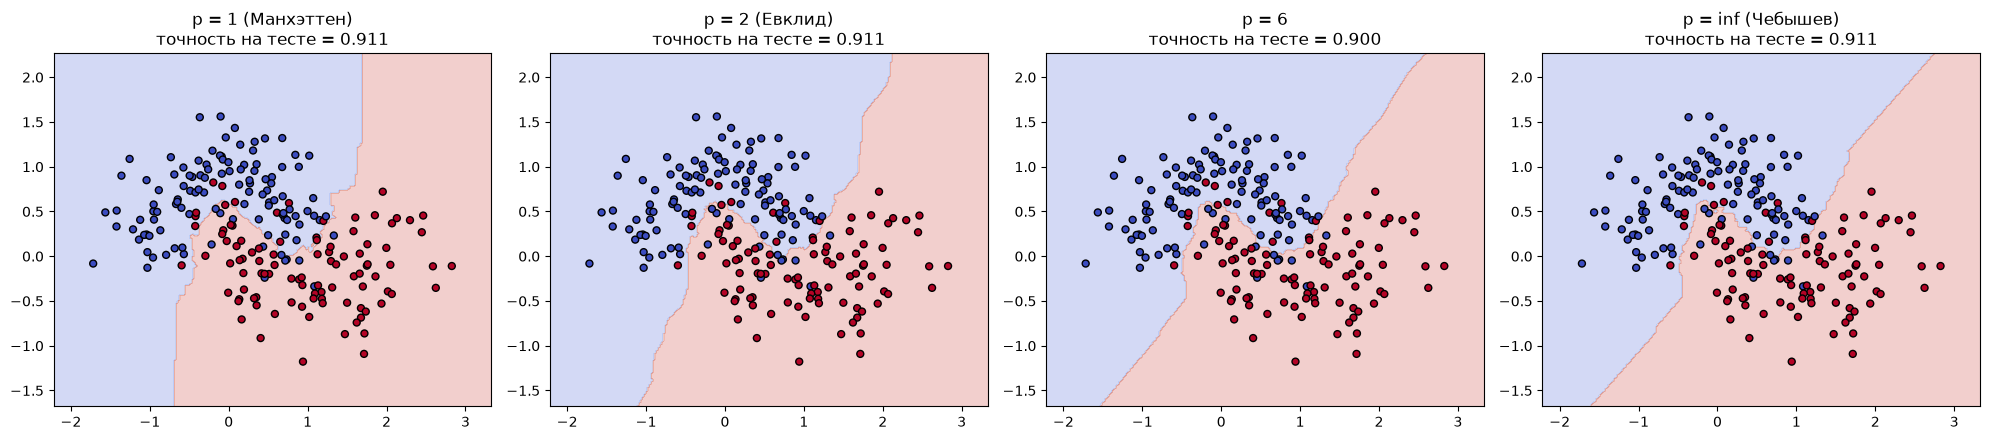

In [12]:
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score

# двумерный бинарный набор данных
Xm, ym = make_moons(n_samples=300, noise=0.3, random_state=RANDOM_STATE)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=RANDOM_STATE)

# построим границы принятия решений для разных p (inf = Чебышев)
xx, yy = np.meshgrid(np.linspace(Xm[:, 0].min() - .5, Xm[:, 0].max() + .5, 250),
                     np.linspace(Xm[:, 1].min() - .5, Xm[:, 1].max() + .5, 250))
grid = np.c_[xx.ravel(), yy.ravel()]

settings = [('p = 1 (Манхэттен)', dict(p=1)),
            ('p = 2 (Евклид)', dict(p=2)),
            ('p = 6', dict(p=6)),
            ('p = inf (Чебышев)', dict(metric='chebyshev'))]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (title, params) in zip(axes, settings):
    knn_m = KNeighborsClassifier(n_neighbors=15, **params).fit(Xm_tr, ym_tr)
    zz = knn_m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=.25, cmap='coolwarm')
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=ym_tr, cmap='coolwarm', edgecolor='k', s=25)
    acc = accuracy_score(ym_te, knn_m.predict(Xm_te))
    ax.set_title(f'{title}\nточность на тесте = {acc:.3f}')
plt.tight_layout()
plt.show()

**Что мы сделали:** написали функцию расстояния Минковского $d_p(x, y) = \left(\sum_i |x_i - y_i|^p\right)^{1/p}$ (для $p=\infty$ она превращается в $\max_i |x_i - y_i|$) и проверили её на точках $(0,0)$ и $(3,4)$: при $p=1$ получаем 7, при $p=2$ получаем 5, при росте $p$ расстояние стремится к 4 (это расстояние Чебышева). Затем обучили KNN (k=15) на синтетических данных «две луны» с разными $p$ и нарисовали границы классов.

**Что видно на графиках:** форма «шара» (множества точек на одном расстоянии от центра) зависит от $p$: при $p=1$ это ромб, при $p=2$ круг, при $p \to \infty$ квадрат. Поэтому и граница принятия решения меняется: при $p=1$ и $p=\infty$ она более «угловатая» и подстроена под направления осей, при $p=2$ она самая гладкая. Точность на тесте при этом почти одинакова (около 0,90-0,91 для всех $p$), то есть на таком наборе выбор метрики мало влияет на качество, но геометрия границ заметно отличается. На реальных данных с признаками разного типа выбор $p$ может влиять сильнее.

### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [13]:
# Эксперимент с K=1 на обучающей выборке (обучаем и предсказываем на всех данных)
def acc(model):
    model.fit(X_all_s, y)
    return (model.predict(X_all_s) == y).mean()

print('K=1,  uniform :', acc(KNeighborsClassifier(n_neighbors=1)))
print('K=3,  distance:', acc(KNeighborsClassifier(n_neighbors=3, weights='distance')))
print('K=3,  uniform :', acc(KNeighborsClassifier(n_neighbors=3)))
print('K=15, uniform :', acc(KNeighborsClassifier(n_neighbors=15)))
print('Доля класса 0 (константный прогноз):', round((y == 0).mean(), 4))

K=1,  uniform : 1.0
K=3,  distance: 1.0
K=3,  uniform : 0.9422
K=15, uniform : 0.9098
Доля класса 0 (константный прогноз): 0.8586


**Что мы сделали:** обучили KNN на всех данных и предсказали на тех же данных (без разделения на train/test) для разных $K$ и типов весов.

**Объяснение.** KNN не «обучается» в обычном смысле: модель - это сами данные, `fit` их только запоминает. Если в обучающей выборке есть точка $x_i$ и мы предсказываем для неё же, то ближайший сосед $x_i$ - это сама точка на расстоянии $d(x_i, x_i) = 0$. При $K=1$ предсказание равно её собственной метке, поэтому точность 100%. При `weights='distance'` вес соседа равен $1/d$, то есть для самой точки он бесконечно велик (на практике scikit-learn просто берёт соседа с нулевым расстоянием), поэтому голос собственной метки перевешивает остальных и точность тоже получается 1.0. Это и есть запоминание (экстремальное переобучение): модель идеальна на данных, которые видела, но это ничего не говорит о качестве на новых данных. При обычных равномерных весах и $K=3$ или $K=15$ собственная точка - лишь один из голосов, поэтому точность ниже 100%. Вывод: качество нужно оценивать на отложенных данных или перекрёстной проверкой (следующее упражнение).

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [14]:
class CustomKNN:
    def __init__(self):
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y).astype(int)
        return self

    def predict(self, X_test, k=3):
        X_test = np.asarray(X_test, dtype=float)

        # квадраты евклидовых расстояний сразу для всех пар без циклов:
        # |a - b|^2 = |a|^2 + |b|^2 - 2*a*b
        d2 = ((X_test ** 2).sum(axis=1)[:, None]
              + (self.X_train ** 2).sum(axis=1)[None, :]
              - 2 * X_test @ self.X_train.T)

        # индексы k ближайших соседей для каждого тестового объекта
        nearest = np.argpartition(d2, k - 1, axis=1)[:, :k]
        neighbor_labels = self.y_train[nearest]

        # мажоритарное голосование: самая частая метка среди соседей
        return np.array([np.bincount(row).argmax() for row in neighbor_labels])

In [15]:
# небольшое подмножество данных: 1500 случайных клиентов
subset = data.sample(1500, random_state=RANDOM_STATE)
Xs = subset.drop(columns='churned')
ys = subset['churned']
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=RANDOM_STATE, stratify=ys)

sc = MinMaxScaler().fit(Xs_tr)
Xs_tr_s, Xs_te_s = sc.transform(Xs_tr), sc.transform(Xs_te)

my_knn = CustomKNN().fit(Xs_tr_s, ys_tr)
my_pred = my_knn.predict(Xs_te_s, k=5)

sk_pred = KNeighborsClassifier(n_neighbors=5).fit(Xs_tr_s, ys_tr).predict(Xs_te_s)

print('Точность CustomKNN :', round((my_pred == ys_te.values).mean(), 4))
print('Точность sklearn   :', round((sk_pred == ys_te.values).mean(), 4))
print('Доля совпавших предсказаний:', round((my_pred == sk_pred).mean(), 4))

Точность CustomKNN : 0.9289
Точность sklearn   : 0.9289
Доля совпавших предсказаний: 1.0


**Что мы сделали:** написали класс `CustomKNN` без `sklearn`. В `fit` он просто запоминает данные. В `predict` для всех тестовых объектов сразу считаются квадраты евклидовых расстояний до всех обучающих объектов (через формулу $|a-b|^2 = |a|^2 + |b|^2 - 2ab$ и умножение матриц, поэтому без медленных циклов), затем `argpartition` выбирает $k$ ближайших соседей, а `bincount` определяет самую частую метку (мажоритарное голосование). Проверили на подмножестве из 1500 клиентов, сравнив с `KNeighborsClassifier`: предсказания совпали полностью (100% совпадений, точность одинаковая). Небольшие расхождения были бы возможны только при равных расстояниях до соседей.

### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

In [16]:
from sklearn.model_selection import StratifiedKFold

# Напишите код кросс-валидации
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_values = range(1, 31)

cv_mean, cv_std = [], []
for k in k_values:
    fold_acc = []
    for tr_idx, val_idx in skf.split(X_train, y_train):
        # масштабирование подгоняем только на обучающей части фолда
        sc_f = MinMaxScaler().fit(X_train.iloc[tr_idx])
        Xtr_f = sc_f.transform(X_train.iloc[tr_idx])
        Xval_f = sc_f.transform(X_train.iloc[val_idx])

        knn_f = KNeighborsClassifier(n_neighbors=k).fit(Xtr_f, y_train.iloc[tr_idx])
        fold_acc.append(knn_f.score(Xval_f, y_train.iloc[val_idx]))
    cv_mean.append(np.mean(fold_acc))
    cv_std.append(np.std(fold_acc))

cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)
best_k = list(k_values)[int(np.argmax(cv_mean))]
print('Оптимальное K =', best_k)
print('Средняя точность = %.4f (+/- %.4f)' % (cv_mean.max(), cv_std[np.argmax(cv_mean)]))
print()
print(pd.DataFrame({'K': list(k_values), 'mean_acc': cv_mean.round(4), 'std': cv_std.round(4)}).head(10).to_string(index=False))

Оптимальное K = 5
Средняя точность = 0.8977 (+/- 0.0082)

 K  mean_acc    std
 1    0.8717 0.0066
 2    0.8863 0.0047
 3    0.8971 0.0075
 4    0.8851 0.0089
 5    0.8977 0.0082
 6    0.8869 0.0065
 7    0.8971 0.0072
 8    0.8871 0.0094
 9    0.8943 0.0069
10    0.8874 0.0074


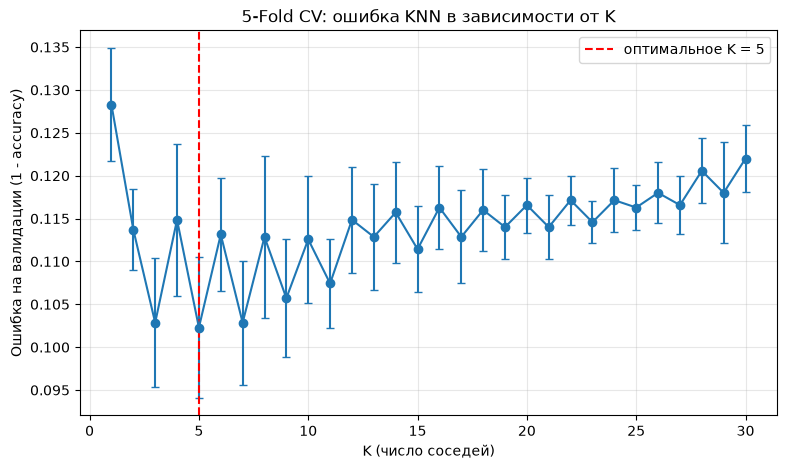

In [17]:
plt.figure(figsize=(9, 5))
plt.errorbar(list(k_values), 1 - cv_mean, yerr=cv_std, fmt='-o', capsize=3)
plt.axvline(best_k, color='red', linestyle='--', label=f'оптимальное K = {best_k}')
plt.xlabel('K (число соседей)')
plt.ylabel('Ошибка на валидации (1 - accuracy)')
plt.title('5-Fold CV: ошибка KNN в зависимости от K')
plt.legend()
plt.grid(alpha=.3)
plt.show()

**Что мы сделали:** на обучающей части данных выполнили 5-fold кросс-валидацию (`StratifiedKFold` сохраняет долю ушедших клиентов в каждом фолде) для $K = 1 \dots 30$. Масштабирование `MinMaxScaler` подгоняли внутри каждого фолда только на его обучающей части, чтобы информация из валидационной части не просачивалась в модель. Для каждого $K$ посчитали среднюю точность и стандартное отклонение, построили график ошибки.

**Вывод:** оптимальное значение $K = 5$ (средняя точность около 0,898 при std около 0,008). При $K=1$ точность заметно ниже (≈ 0,872): модель реагирует на шум и переобучается. Дальше с ростом $K$ ошибка медленно растёт (при $K=30$ точность около 0,878), приближаясь к ошибке константной модели «никто не уйдёт» (около 14%), так как модель всё чаще голосует за мажоритарный класс (подробнее в упражнении 8). Зигзаг на графике (нечётные $K$ чуть лучше чётных) объясняется возможными ничьими при чётном числе голосов. Разброс между фолдами (около 0,7-0,9 п.п.) сопоставим с разницей между соседними $K$, поэтому выбор между, например, $K=3, 5, 7$ статистически не очень надёжен.

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие - меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

In [18]:
from sklearn.metrics import confusion_matrix, classification_report

# Напишите код для расчета метрик
knn8 = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
y_pred8 = knn8.predict(X_test_s)

print('Accuracy модели:', round((y_pred8 == y_test).mean(), 4))
print('Accuracy "всегда не уйдёт":', round((y_test == 0).mean(), 4))
print()

cm = confusion_matrix(y_test, y_pred8)
print('Матрица ошибок (строки - факт, столбцы - прогноз):')
print(pd.DataFrame(cm, index=['факт: остался', 'факт: ушёл'], columns=['прогноз: остался', 'прогноз: ушёл']))
print()
print(classification_report(y_test, y_pred8, target_names=['остался', 'ушёл']))

Accuracy модели: 0.8993
Accuracy "всегда не уйдёт": 0.8587

Матрица ошибок (строки - факт, столбцы - прогноз):
               прогноз: остался  прогноз: ушёл
факт: остался              1263             25
факт: ушёл                  126             86

              precision    recall  f1-score   support

     остался       0.91      0.98      0.94      1288
        ушёл       0.77      0.41      0.53       212

    accuracy                           0.90      1500
   macro avg       0.84      0.69      0.74      1500
weighted avg       0.89      0.90      0.89      1500



**Что мы сделали:** обучили KNN (k=5) и на тестовой выборке посчитали матрицу ошибок и отчёт `classification_report` (precision, recall, F1 для каждого класса). Для сравнения посчитали точность «глупой» модели, которая всегда предсказывает, что клиент останется.

**Почему accuracy вводит в заблуждение.** Ушедших клиентов всего около 14%, поэтому модель, которая всегда говорит «клиент останется», уже имеет accuracy около 86%, хотя не находит ни одного уходящего клиента. Высокая точность получается за счёт мажоритарного класса, а бизнесу важны именно ушедшие клиенты. Поэтому смотрят на другие метрики:
- **Precision** (точность по классу) = $TP / (TP + FP)$: какая доля предсказанных «ушёл» действительно ушла;
- **Recall** (полнота) = $TP / (TP + FN)$: какую долю реально ушедших мы нашли;
- **F1** = $2 \cdot \frac{P \cdot R}{P + R}$: среднее гармоническое двух предыдущих.

В нашем отчёте accuracy модели ≈ 0,90 (против 0,86 у «глупой» модели), но по классу «ушёл» precision ≈ 0,77, а recall всего ≈ 0,41 (F1 ≈ 0,53): из 212 ушедших клиентов модель нашла только 86 и пропустила 126. Общая accuracy выглядит хорошо, но основную цель (найти уходящих клиентов) модель выполняет плохо.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

In [19]:
from sklearn.metrics import f1_score

# Эксперимент с весами
rng = np.random.RandomState(RANDOM_STATE)
n_repeats = 5

def evaluate(Xtr, ytr, weights, k=5):
    m = KNeighborsClassifier(n_neighbors=k, weights=weights).fit(Xtr, ytr)
    pred = m.predict(X_test_s)
    return (pred == y_test.values).mean(), f1_score(y_test, pred)

# (а) шум в признаках: к обучающим данным добавляем гауссов шум разной силы
print('(а) Шум в признаках обучающей выборки')
rows = []
for sigma in [0, 0.05, 0.1, 0.2, 0.4]:
    for w in ['uniform', 'distance']:
        res = []
        for _ in range(n_repeats):
            Xn = X_train_s + rng.normal(0, sigma, X_train_s.shape)
            res.append(evaluate(Xn, y_train, w))
        a_, f_ = np.mean(res, axis=0)
        rows.append({'sigma': sigma, 'weights': w, 'accuracy': round(a_, 4), 'F1(ушёл)': round(f_, 4)})
print(pd.DataFrame(rows).pivot(index='sigma', columns='weights', values=['accuracy', 'F1(ушёл)']))

(а) Шум в признаках обучающей выборки
        accuracy         F1(ушёл)        
weights distance uniform distance uniform
sigma                                    
0.00      0.8987  0.8993   0.5309  0.5325
0.05      0.8965  0.8972   0.4934  0.4889
0.10      0.8793  0.8808   0.3395  0.3596
0.20      0.8640  0.8597   0.2433  0.1988
0.40      0.8556  0.8536   0.0631  0.0740


In [20]:
# (б) шум в метках: случайно переворачиваем долю меток в обучающей выборке
print('(б) Шум в метках обучающей выборки')
rows = []
for frac in [0, 0.05, 0.1, 0.2, 0.3]:
    for w in ['uniform', 'distance']:
        res = []
        for _ in range(n_repeats):
            y_noisy = y_train.values.copy()
            flip = rng.rand(len(y_noisy)) < frac
            y_noisy[flip] = 1 - y_noisy[flip]
            res.append(evaluate(X_train_s, y_noisy, w))
        a_, f_ = np.mean(res, axis=0)
        rows.append({'доля шума': frac, 'weights': w, 'accuracy': round(a_, 4), 'F1(ушёл)': round(f_, 4)})
print(pd.DataFrame(rows).pivot(index='доля шума', columns='weights', values=['accuracy', 'F1(ушёл)']))

(б) Шум в метках обучающей выборки
          accuracy         F1(ушёл)        
weights   distance uniform distance uniform
доля шума                                  
0.00        0.8987  0.8993   0.5309  0.5325
0.05        0.8953  0.8973   0.5257  0.5286
0.10        0.8868  0.8880   0.5087  0.5238
0.20        0.8385  0.8383   0.4248  0.4241
0.30        0.7368  0.7517   0.3234  0.3455


**Что мы сделали:** сравнили `weights='uniform'` (все $K$ соседей голосуют одинаково) и `weights='distance'` (вес соседа $1/d$, то есть ближний влияет сильнее). Провели два эксперимента на обучающей выборке: (а) добавили гауссов шум разной силы к признакам, (б) случайно перевернули часть меток. Для каждого уровня шума повторили опыт 5 раз и усреднили точность и F1 по классу «ушёл» на чистой тестовой выборке.

**Выводы:** по нашим результатам обе схемы ведут себя очень похоже, разница в 1-2 процентных пункта. Качество падает с ростом шума одинаково: F1 по классу «ушёл» с 0,53 при чистых данных снижается до 0,06-0,07 при сильном шуме в признаках ($\sigma = 0{,}4$). При шуме в метках `uniform` держится чуть лучше (например, при 30% шума F1 0,35 против 0,32, а accuracy 0,75 против 0,74), хотя при шуме признаков $\sigma=0{,}2$ лучше оказался `distance`. Такие различия сопоставимы со случайным разбросом (опыт повторён всего 5 раз), поэтому уверенно утверждать преимущество нельзя.

Теоретически более уязвим к шуму `weights='distance'`: вес соседа $1/d$ неограниченно растёт, когда точка оказывается очень близко. Если рядом с тестовым объектом случайно оказался выброс или объект с неправильной меткой, он получает огромный вес и может в одиночку перевесить остальных соседей. При `uniform` такой объект - лишь один голос из $K$, и его перекрывают остальные. Эффект сильнее при малых $K$. В нашем случае он слабо виден, потому что 17 признаков делают расстояния до пяти соседей примерно одинаковыми (веса почти равны), и `distance` практически превращается в `uniform`.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

In [21]:
# Эксперимент с проклятием размерности
rng10 = np.random.RandomState(RANDOM_STATE)
rows = []
for n_noise in [0, 5, 10, 20, 50, 100, 200]:
    # добавляем столбцы равномерного шума [0, 1] - такого же масштаба, как и остальные признаки
    noise_tr = rng10.rand(X_train_s.shape[0], n_noise)
    noise_te = rng10.rand(X_test_s.shape[0], n_noise)
    Xtr_n = np.hstack([X_train_s, noise_tr])
    Xte_n = np.hstack([X_test_s, noise_te])

    m = KNeighborsClassifier(n_neighbors=5).fit(Xtr_n, y_train)
    pred = m.predict(Xte_n)

    # насколько "одинаково далеки" объекты: (d_max - d_min) / d_min для одного тестового объекта
    d = np.sqrt(((Xtr_n - Xte_n[0]) ** 2).sum(axis=1))
    contrast = (d.max() - d.min()) / d.min()

    rows.append({'шумовых признаков': n_noise, 'всего признаков': Xtr_n.shape[1],
                 'accuracy': round((pred == y_test.values).mean(), 4),
                 'F1(ушёл)': round(f1_score(y_test, pred), 4),
                 'контраст расстояний': round(contrast, 2)})
dim_df = pd.DataFrame(rows)
print(dim_df.to_string(index=False))

 шумовых признаков  всего признаков  accuracy  F1(ушёл)  контраст расстояний
                 0               17    0.8993    0.5325                 9.64
                 5               22    0.8800    0.3478                 4.74
                10               27    0.8640    0.2214                 3.20
                20               37    0.8567    0.1887                 1.42
                50               67    0.8527    0.0753                 0.90
               100              117    0.8527    0.0596                 0.51
               200              217    0.8533    0.0909                 0.31


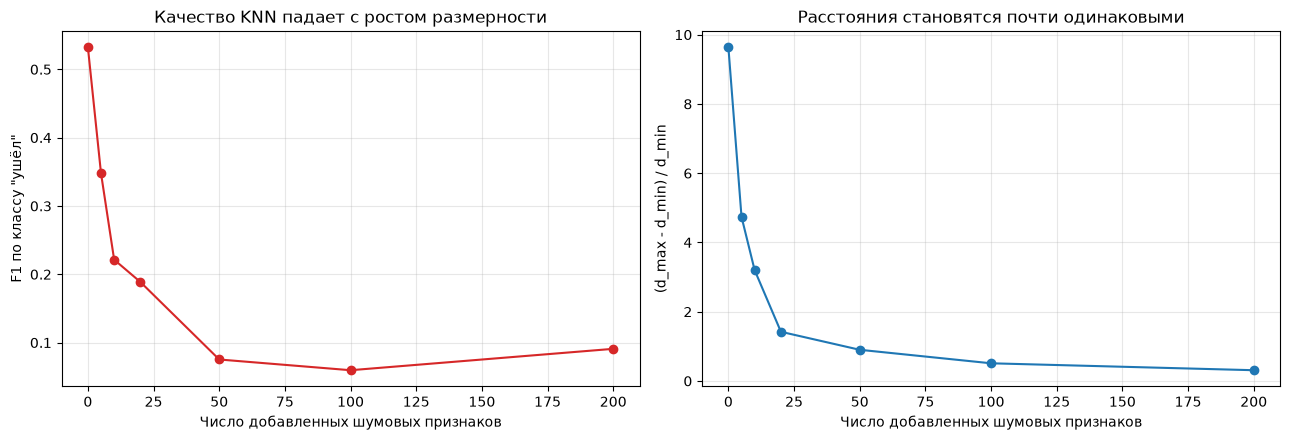

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(dim_df['шумовых признаков'], dim_df['F1(ушёл)'], '-o', color='tab:red')
ax[0].set_xlabel('Число добавленных шумовых признаков')
ax[0].set_ylabel('F1 по классу "ушёл"')
ax[0].set_title('Качество KNN падает с ростом размерности')
ax[0].grid(alpha=.3)

ax[1].plot(dim_df['шумовых признаков'], dim_df['контраст расстояний'], '-o', color='tab:blue')
ax[1].set_xlabel('Число добавленных шумовых признаков')
ax[1].set_ylabel('(d_max - d_min) / d_min')
ax[1].set_title('Расстояния становятся почти одинаковыми')
ax[1].grid(alpha=.3)
plt.tight_layout()
plt.show()

**Что мы сделали:** к 17 настоящим (отмасштабированным) признакам добавляли 5, 10, 20, 50, 100 и 200 столбцов случайного шума из $U[0,1]$ и каждый раз обучали KNN (k=5). Кроме качества (accuracy и F1 по классу «ушёл») считали «контраст расстояний» $(d_{max} - d_{min}) / d_{min}$ от тестового объекта до обучающих.

**Результат:** с ростом числа шумовых признаков F1 по классу «ушёл» резко падает: с 0,53 (17 признаков) до 0,35 при 5 шумовых и до 0,06-0,09 при 50 и более. Accuracy снижается с 0,90 до 0,85, то есть до уровня «глупой» модели, которая всегда предсказывает «остался» (0,86): модель практически перестаёт находить уходящих клиентов.

**Объяснение:** каждый шумовой признак вносит в квадрат расстояния случайное слагаемое $(u_i - v_i)^2$ со средним $1/6$, которое никак не связано с оттоком. Полезные признаки составляют всё меньшую долю суммы, и ближайшие соседи выбираются почти случайно. Кроме того, с ростом размерности расстояния концентрируются: контраст $(d_{max} - d_{min}) / d_{min}$ падает с 9,6 до 0,3, то есть самая далёкая точка лишь немного дальше самой близкой, и понятие «ближайший сосед» теряет смысл. Для KNN это значит, что перед обучением нужно отбирать признаки (как в упражнении 12) или уменьшать размерность (PCA).

### Упражнение 11: KNN для регрессии против классификации
Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE - Mean Squared Error) для различных значений K.

In [23]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

# Ваш код регрессии
# предсказываем total_day_charge по минутам и числу звонков
Xr = data[['total_day_minutes', 'total_day_calls']]
yr = data['total_day_charge']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.3, random_state=RANDOM_STATE)

sc_r = MinMaxScaler().fit(Xr_tr)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

mse_rows = []
for k in [1, 3, 5, 10, 20, 50, 100, 200]:
    reg = KNeighborsRegressor(n_neighbors=k).fit(Xr_tr_s, yr_tr)
    mse_rows.append({'K': k,
                     'MSE train': round(mean_squared_error(yr_tr, reg.predict(Xr_tr_s)), 4),
                     'MSE test': round(mean_squared_error(yr_te, reg.predict(Xr_te_s)), 4)})
mse_df = pd.DataFrame(mse_rows)
print(mse_df.to_string(index=False))
print('\nДисперсия целевой переменной на тесте (для сравнения): %.2f' % yr_te.var())

  K  MSE train  MSE test
  1     0.0000    0.8459
  3     0.0584    0.6973
  5     0.0777    0.4694
 10     0.1312    0.5576
 20     0.2571    0.7121
 50     0.6905    1.2800
100     1.3902    2.0713
200     2.8483    3.6842

Дисперсия целевой переменной на тесте (для сравнения): 85.99


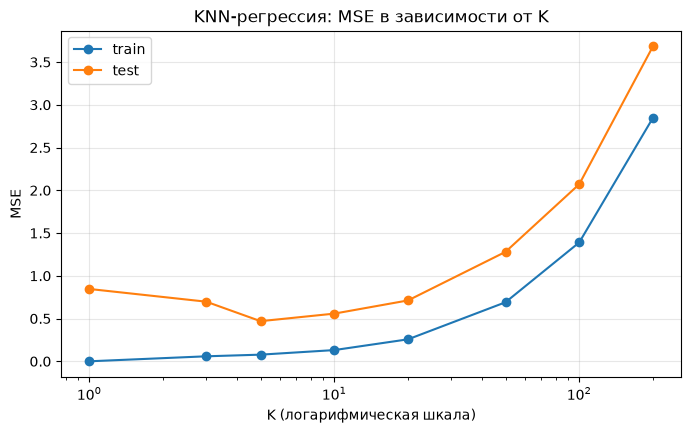

In [24]:
plt.figure(figsize=(8, 4.5))
plt.plot(mse_df['K'], mse_df['MSE train'], '-o', label='train')
plt.plot(mse_df['K'], mse_df['MSE test'], '-o', label='test')
plt.xscale('log')
plt.xlabel('K (логарифмическая шкала)')
plt.ylabel('MSE')
plt.title('KNN-регрессия: MSE в зависимости от K')
plt.legend()
plt.grid(alpha=.3)
plt.show()

**Что мы сделали:** применили `KNeighborsRegressor` для предсказания `total_day_charge` по `total_day_minutes` и `total_day_calls` (признаки отмасштабированы). Для $K$ от 1 до 200 посчитали MSE на обучающей и тестовой выборках. В регрессии прогноз - это среднее значение целевой переменной у $K$ ближайших соседей, а не голосование.

**Вывод:** при $K=1$ ошибка на train равна нулю (каждая точка - сама себе сосед, ср. упражнение 5), а на тесте ошибка выше. При росте $K$ усреднение сглаживает прогноз: ошибка на тесте сначала падает, затем при слишком больших $K$ снова растёт, так как модель становится слишком грубой (недообучение). Лучшее $K$ находится посередине: $K=5$ даёт минимальный MSE на тесте (≈ 0,47), при $K=1$ он ≈ 0,85, а при $K=200$ вырастает до ≈ 3,7. Заметим, что `total_day_charge` практически линейно зависит от `total_day_minutes` (тариф около 0,17 за минуту), поэтому все значения MSE очень малы по сравнению с дисперсией целевой переменной. Для такой гладкой зависимости линейная регрессия сработала бы лучше KNN, но цель упражнения - показать влияние $K$.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif

# Настройка Pipeline и GridSearchCV
pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest(score_func=f_classif)),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'select__k': [5, 10, 'all'],          # селектор признаков (опционально, 'all' = без отбора)
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

# из-за дисбаланса классов оптимизируем F1 по классу "ушёл", а не accuracy
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print('Лучшие гиперпараметры:', grid.best_params_)
print('Лучший F1 на кросс-валидации: %.4f' % grid.best_score_)

best_model = grid.best_estimator_
y_pred12 = best_model.predict(X_test)
print('\nОценка на тестовой выборке:')
print('accuracy = %.4f, F1 = %.4f' % ((y_pred12 == y_test).mean(), f1_score(y_test, y_pred12)))
print()
print(classification_report(y_test, y_pred12, target_names=['остался', 'ушёл']))

Лучшие гиперпараметры: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance', 'select__k': 10}
Лучший F1 на кросс-валидации: 0.6493

Оценка на тестовой выборке:
accuracy = 0.9100, F1 = 0.5994

              precision    recall  f1-score   support

     остался       0.92      0.98      0.95      1288
        ушёл       0.81      0.48      0.60       212

    accuracy                           0.91      1500
   macro avg       0.86      0.73      0.77      1500
weighted avg       0.90      0.91      0.90      1500



In [26]:
# какие признаки выбрал селектор (если выбор был не 'all')
selector = best_model.named_steps['select']
selected = X.columns[selector.get_support()]
print('Использовано признаков:', len(selected))
print(list(selected))

Использовано признаков: 10
['intl_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_charge', 'total_eve_minutes', 'total_eve_charge', 'total_intl_minutes', 'total_intl_charge', 'number_customer_service_calls']


**Что мы сделали:** собрали пайплайн из трёх шагов: `MinMaxScaler` → `SelectKBest` → `KNeighborsClassifier`, и с помощью `GridSearchCV` (5-fold) перебрали число соседей $K \in \{3,5,7,9,11\}$, тип весов (`uniform`/`distance`), параметр метрики $p \in \{1, 2\}$ и число отбираемых признаков (5, 10 или все). Благодаря `Pipeline` масштабирование и отбор признаков подгоняются заново внутри каждого фолда, поэтому утечки данных нет. Так как классы несбалансированы, качество подбирали по F1 для класса «ушёл». Лучшие гиперпараметры: $K=5$, `weights='distance'`, $p=1$ (расстояние Манхэттена), отбор 10 признаков из 17. На тестовой выборке accuracy ≈ 0,91 и F1 ≈ 0,60 (против F1 ≈ 0,53 у обычного KNN из упражнения 8). Recall по классу «ушёл» вырос до ≈ 0,48, но всё ещё остаётся невысоким: KNN на этих данных находит менее половины уходящих клиентов. Селектор оставил признаки, связанные с тарифами, минутами разговоров и звонками в службу поддержки (список выведен выше).

## Общий вывод

Мы разобрали KNN на данных об оттоке клиентов: масштабирование обязательно, потому что расстояния зависят от масштаба признаков; идентификаторы вроде номера телефона использовать нельзя; точность на обучающей выборке ничего не показывает (KNN запоминает данные), нужна кросс-валидация; при несбалансированных классах следует смотреть precision, recall и F1; KNN чувствителен к шуму и к лишним признакам (проклятие размерности), а подбор гиперпараметров удобно делать через `Pipeline` и `GridSearchCV`.